<a href="https://colab.research.google.com/github/ikhyun00/Kaggle-Student-Score-Predict/blob/main/Kaggle_%EC%8B%9C%ED%97%98%EC%A0%90%EC%88%98%EC%98%88%EC%B8%A1_%EB%A9%94%EC%9D%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kaggle 시험 점수 예측 — 통계 분석

**질문**
1. 어떤 변수가 시험 점수와 가장 강하게 연결되는가?
2. 그 차이는 통계적으로 유의한 것을 넘어, 실질적으로 의미 있는 크기인가?
3. 가장 중요한 변수인 학습 시간은 다른 변수로 설명되는가?

**방법**
- 63만 행이라 아주 작은 차이도 p < 0.05가 나온다. 표본을 줄여 p값을 맞추는 대신 **전체 데이터**로 분석하고, 판단은 **효과크기와 신뢰구간**으로 한다.
- 수치형: Spearman 순위상관 ρ / 범주형: ANOVA η²·ω² / 두 집단: Welch t-검정 + Cohen's d
- 효과크기 기준(Cohen): ρ 0.1 작음 · 0.3 중간 · 0.5 큼 / η² 0.01 작음 · 0.06 중간 · 0.14 큼 / d 0.2 작음 · 0.5 중간 · 0.8 큼

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
import pingouin as pg

for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if f in {x.name for x in plt.matplotlib.font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

DATA_PATH = "data/"
df = pd.read_csv(DATA_PATH + "train.csv")

TOP_K_COURSE = 20
TOP_K_STUDY_METHOD = 20

In [2]:
# ============================================================
# 1) 유틸 함수
# ============================================================
def normalize_str_series(s):
    if not pd.api.types.is_string_dtype(s):
        return s
    return s.astype(str).str.strip().str.lower().replace({"nan": np.nan})

def try_make_numeric(df, cols):
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

def reduce_to_top_k(df, col, k):
    if col not in df.columns:
        return df
    top = df[col].value_counts(dropna=True).head(k).index
    df[col] = df[col].where(df[col].isin(top), other="other")
    return df

def cohen_d(x, y):
    x, y = pd.Series(x).dropna().astype(float), pd.Series(y).dropna().astype(float)
    nx, ny = len(x), len(y)
    if nx < 2 or ny < 2:
        return np.nan
    vx, vy = x.var(ddof=1), y.var(ddof=1)
    pooled = ((nx-1)*vx + (ny-1)*vy) / (nx+ny-2)
    if pooled <= 0:
        return np.nan
    return float((x.mean() - y.mean()) / np.sqrt(pooled))

def eta_squared(aov, effect):
    if effect not in aov.index or "sum_sq" not in aov.columns:
        return np.nan
    ss_total = aov["sum_sq"].sum()
    if ss_total == 0:
        return np.nan
    return float(aov.loc[effect, "sum_sq"] / ss_total)

def omega_squared(aov, effect):
    if effect not in aov.index:
        return np.nan
    ss_effect = aov.loc[effect, "sum_sq"]
    df_effect = aov.loc[effect, "df"]
    ss_error = aov.loc["Residual", "sum_sq"]
    df_error = aov.loc["Residual", "df"]
    ms_error = ss_error / df_error
    ss_total = aov["sum_sq"].sum()
    w2 = (ss_effect - df_effect * ms_error) / (ss_total + ms_error)
    return float(max(0.0, w2))

In [3]:
# ============================================================
# 2) 전처리
# ============================================================
for drop_col in ["id", "ID", "Id", "index"]:
    if drop_col in df.columns:
        df = df.drop(columns=[drop_col])

df = try_make_numeric(df, ["age", "study_hours", "sleep_hours", "class_attendance"])

for c in ["gender", "course", "internet_access", "sleep_quality",
          "study_method", "facility_rating", "exam_difficulty"]:
    if c in df.columns:
        df[c] = normalize_str_series(df[c])

ORDERS = {
    "sleep_quality": ["poor", "average", "good"],
    "facility_rating": ["low", "medium", "high"],
    "exam_difficulty": ["easy", "moderate", "hard"]
}
for col, order in ORDERS.items():
    if col in df.columns:
        df[col] = pd.Categorical(df[col], categories=order, ordered=True)

df = reduce_to_top_k(df, "course", TOP_K_COURSE)
df = reduce_to_top_k(df, "study_method", TOP_K_STUDY_METHOD)

df = df.drop_duplicates()

print("Cleaned shape:", df.shape)

TARGET = "exam_score"

Cleaned shape: (630000, 12)


## 1. 수치형 변수와 시험 점수: Spearman 순위상관

직선 관계가 아니어도 한쪽이 커질 때 다른 쪽도 커지는(단조) 관계를 잡기 위해 순위상관을 쓴다. 95% 신뢰구간은 Fisher z 변환으로 계산한다.

In [4]:
NUM_COLS = ["study_hours", "class_attendance", "sleep_hours", "age"]

def spearman_ci(x, y, alpha=0.05):
    rho, p = stats.spearmanr(x, y)
    z, se = np.arctanh(rho), 1 / np.sqrt(len(x) - 3)
    zc = stats.norm.ppf(1 - alpha / 2)
    return rho, np.tanh(z - zc * se), np.tanh(z + zc * se), p

num_rows = []
for c in NUM_COLS:
    d = df[[c, TARGET]].dropna()
    rho, lo, hi, p = spearman_ci(d[c], d[TARGET])
    num_rows.append({"변수": c, "rho": rho, "CI_low": lo, "CI_high": hi, "p": p})
num_df = pd.DataFrame(num_rows).sort_values("rho", key=np.abs, ascending=False)
display(num_df.round(4))

,변수,rho,CI_low,CI_high,p
0,study_hours,0.7698,0.7687,0.7708,0.0
1,class_attendance,0.3515,0.3493,0.3537,0.0
2,sleep_hours,0.1600,0.1576,0.1625,0.0
3,age,0.0072,0.0047,0.0096,0.0


## 2. 범주형 변수와 시험 점수: ANOVA 효과크기

η²는 집단 간 차이가 전체 변동의 몇 %를 설명하는지, ω²는 표본 크기에 따른 과대추정을 보정한 값이다. 집단 간 분산이 다를 수 있어 Levene 검정과 이분산에 강건한(HC3) 검정을 함께 본다.

In [5]:
CAT_COLS = ["sleep_quality", "study_method", "facility_rating", "exam_difficulty", "gender", "course", "internet_access"]

cat_rows = []
for c in CAT_COLS:
    d = df[[c, TARGET]].dropna()
    m = smf.ols(f"{TARGET} ~ C({c})", data=d).fit()
    aov = anova_lm(m, typ=2)
    aov_r = anova_lm(m, typ=2, robust="hc3")
    eff = f"C({c})"
    groups = [g[TARGET].values for _, g in d.groupby(c, observed=True)]
    cat_rows.append({
        "변수": c,
        "집단 수": len(groups),
        "eta_squared": eta_squared(aov, eff),
        "omega_squared": omega_squared(aov, eff),
        "F": aov.loc[eff, "F"],
        "p": aov.loc[eff, "PR(>F)"],
        "p_robust(HC3)": aov_r.loc[eff, "PR(>F)"],
        "Levene p": stats.levene(*groups, center="median").pvalue,
    })
cat_df = pd.DataFrame(cat_rows).sort_values("eta_squared", ascending=False)
display(cat_df.round(4))

,변수,집단 수,eta_squared,omega_squared,F,p,p_robust(HC3),Levene p
0,sleep_quality,3,0.0561,0.0561,18739.1856,0.0000,0.0000,0.0000
1,study_method,5,0.0501,0.0501,8304.2885,0.0000,0.0000,0.0000
2,facility_rating,3,0.0357,0.0357,11664.9660,0.0000,0.0000,0.0187
5,course,7,0.0003,0.0003,32.5178,0.0000,0.0000,0.0000
4,gender,3,0.0002,0.0002,55.4279,0.0000,0.0000,0.0000
3,exam_difficulty,3,0.0001,0.0001,29.7445,0.0000,0.0000,0.0000
6,internet_access,2,0.0000,0.0000,0.1260,0.7226,0.7272,0.0000


## 3. 인터넷 접근 여부: Welch t-검정 + Cohen's d

yes 57.9만 명 vs no 5.1만 명으로 크기가 매우 다르지만, Welch t-검정은 집단 크기와 분산이 달라도 쓸 수 있어 전체 데이터로 그대로 검정한다.

In [6]:
yes = df.loc[df["internet_access"] == "yes", TARGET]
no = df.loc[df["internet_access"] == "no", TARGET]
tt = stats.ttest_ind(yes, no, equal_var=False)
diff = yes.mean() - no.mean()
se = np.sqrt(yes.var(ddof=1) / len(yes) + no.var(ddof=1) / len(no))
dfw = se**4 / ((yes.var(ddof=1) / len(yes))**2 / (len(yes) - 1) + (no.var(ddof=1) / len(no))**2 / (len(no) - 1))
tc = stats.t.ppf(0.975, dfw)

display(pd.DataFrame([{
    "n_yes": len(yes), "n_no": len(no),
    "mean_yes": yes.mean(), "mean_no": no.mean(),
    "diff(yes-no)": diff, "CI_low": diff - tc * se, "CI_high": diff + tc * se,
    "t": tt.statistic, "p": tt.pvalue, "cohen_d": cohen_d(yes, no),
}]).round(4))

,n_yes,n_no,mean_yes,mean_no,diff(yes-no),CI_low,CI_high,t,p,cohen_d
0,579423,50577,62.5092,62.478,0.0311,-0.1438,0.206,0.3489,0.7272,0.0016


## 4. 사후검정: 효과가 있는 범주형 변수의 집단별 차이

η²가 0.01 이상인 변수만 어느 집단 사이에서 차이가 나는지 본다. Levene 검정에서 분산이 같다고 보기 어려워 Games-Howell 검정을 쓰고, 차이의 크기는 Hedges' g로 본다.

In [7]:
POSTHOC_COLS = cat_df.loc[cat_df["eta_squared"] >= 0.01, "변수"].tolist()
for c in POSTHOC_COLS:
    d = df[[c, TARGET]].dropna().copy()
    d[c] = d[c].astype(str)
    gh = pg.pairwise_gameshowell(data=d, dv=TARGET, between=c)
    print(f"[{c}]")
    display(gh[[k for k in gh.columns if k in ("A", "B", "diff", "pval", "hedges") or k.startswith("mean")]].round(3))

[sleep_quality]


,A,B,mean_A,mean_B,diff,pval,hedges
0,average,good,62.662,67.885,-5.223,0.0,-0.285
1,average,poor,62.662,56.995,5.667,0.0,0.306
2,good,poor,67.885,56.995,10.889,0.0,0.596


[study_method]


,A,B,mean_A,mean_B,diff,pval,hedges
0,coaching,group study,69.267,60.532,8.735,0.0,0.476
1,coaching,mixed,69.267,65.102,4.165,0.0,0.227
2,coaching,online videos,69.267,59.728,9.539,0.0,0.513
3,coaching,self-study,69.267,57.700,11.567,0.0,0.625
4,group study,mixed,60.532,65.102,-4.570,0.0,-0.251
5,group study,online videos,60.532,59.728,0.804,0.0,0.044
6,group study,self-study,60.532,57.700,2.832,0.0,0.154
7,mixed,online videos,65.102,59.728,5.374,0.0,0.291
8,mixed,self-study,65.102,57.700,7.402,0.0,0.402
9,online videos,self-study,59.728,57.700,2.027,0.0,0.109


[facility_rating]


,A,B,mean_A,mean_B,diff,pval,hedges
0,high,low,66.707,57.955,8.753,0.0,0.472
1,high,medium,66.707,63.029,3.678,0.0,0.198
2,low,medium,57.955,63.029,-5.074,0.0,-0.273


## 5. 효과크기 비교와 집단별 평균

변수별로 시험 점수 변동을 얼마나 설명하는지 같은 잣대로 비교하기 위해 수치형은 ρ², 범주형은 η²로 나타낸다. 집단별 평균 그래프는 y축을 0부터 그려 차이의 실제 크기를 보여 준다.

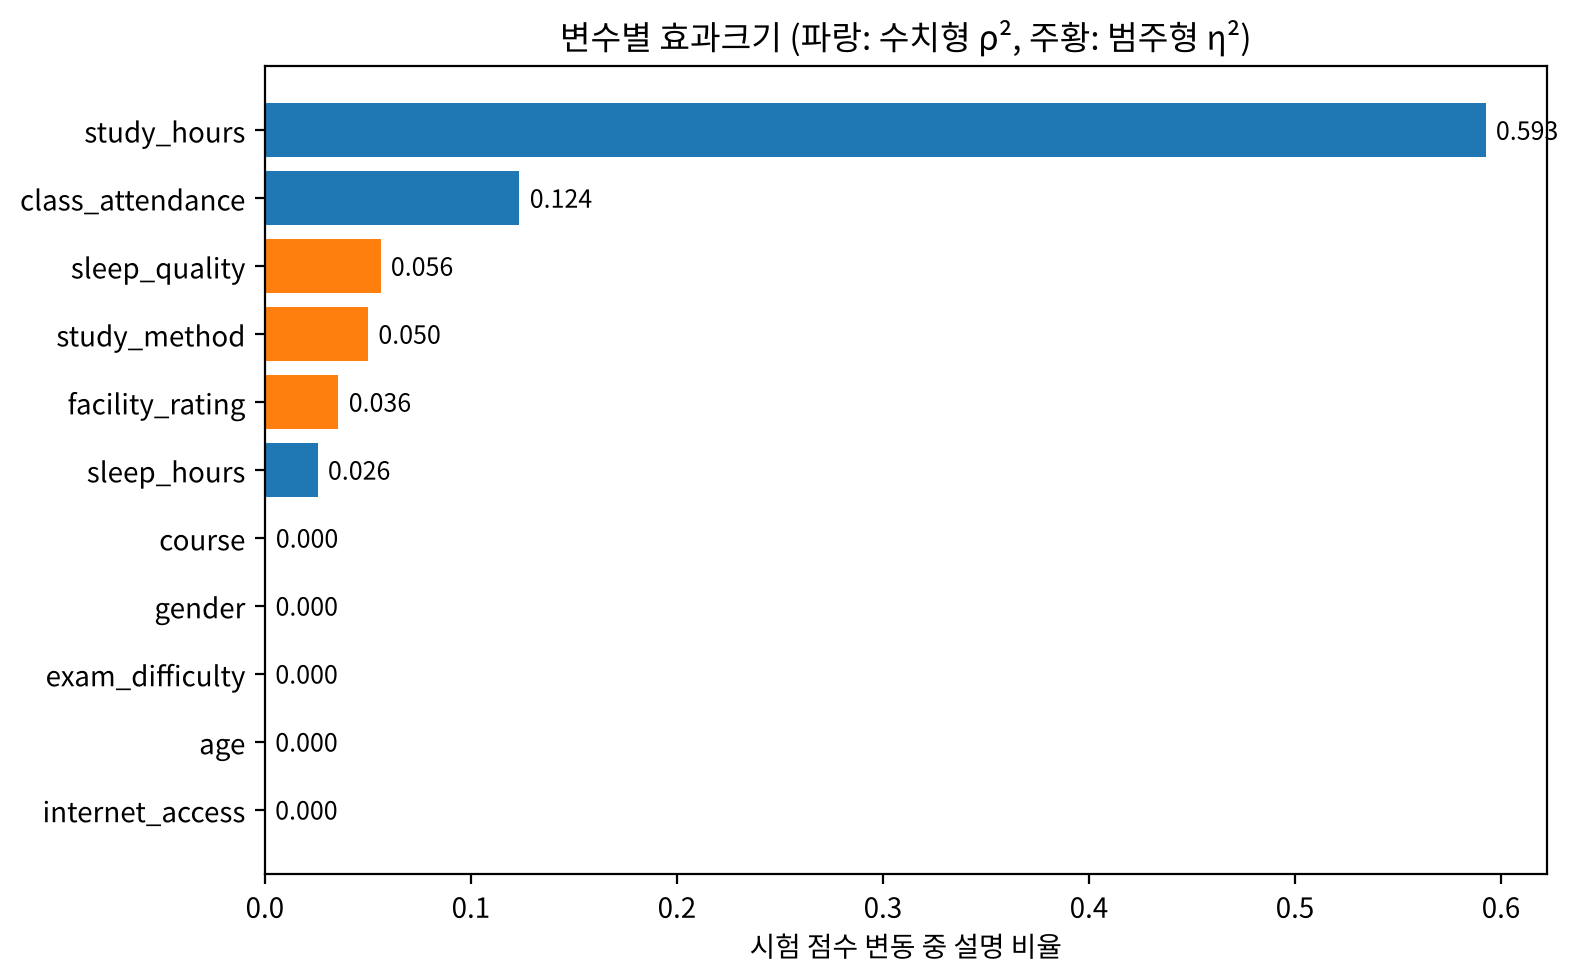

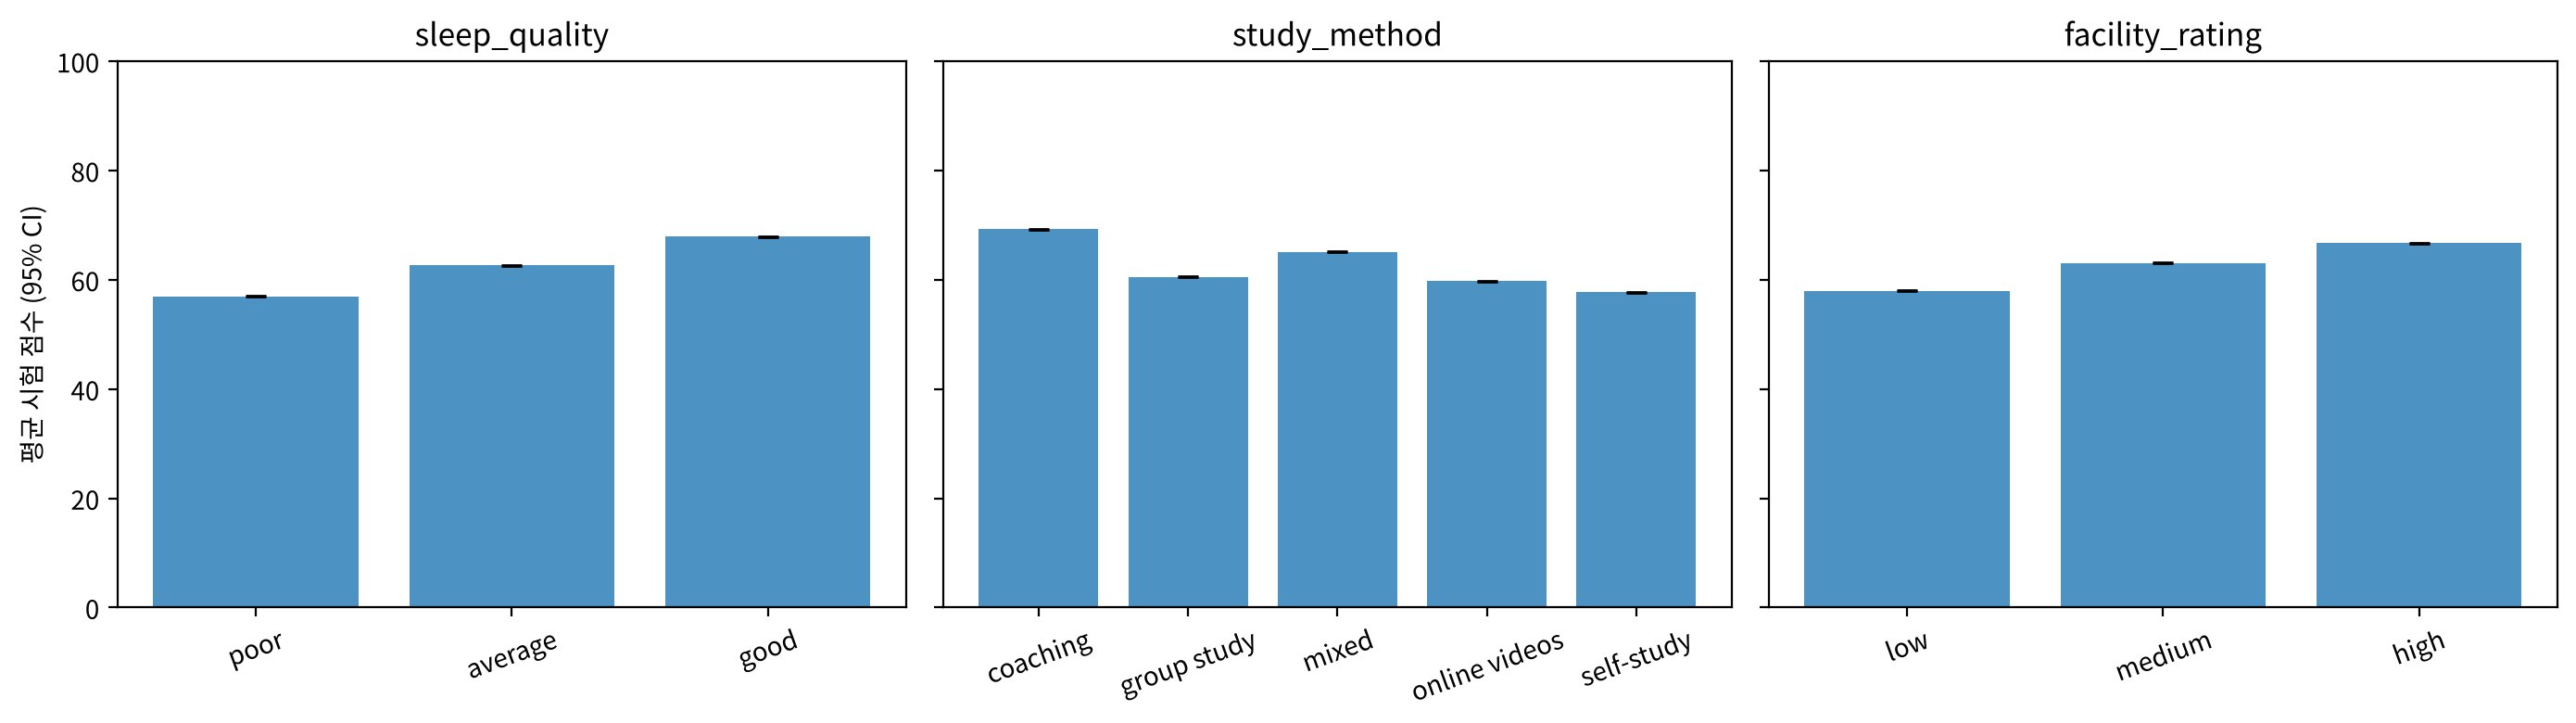

In [8]:
eff = pd.concat([
    pd.DataFrame({"변수": num_df["변수"], "설명 비율": num_df["rho"]**2, "구분": "수치형 (ρ²)"}),
    pd.DataFrame({"변수": cat_df["변수"], "설명 비율": cat_df["eta_squared"], "구분": "범주형 (η²)"}),
]).sort_values("설명 비율")

fig, ax = plt.subplots(figsize=(8, 5))
colors = eff["구분"].map({"수치형 (ρ²)": "tab:blue", "범주형 (η²)": "tab:orange"})
ax.barh(eff["변수"], eff["설명 비율"], color=colors)
for y_, v in enumerate(eff["설명 비율"]):
    ax.text(v + 0.005, y_, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("시험 점수 변동 중 설명 비율")
ax.set_title("변수별 효과크기 (파랑: 수치형 ρ², 주황: 범주형 η²)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, c in zip(axes, ["sleep_quality", "study_method", "facility_rating"]):
    g = df.groupby(c, observed=True)[TARGET].agg(["mean", "std", "count"])
    g["ci"] = 1.96 * g["std"] / np.sqrt(g["count"])
    ax.bar(g.index.astype(str), g["mean"], yerr=g["ci"], capsize=4, color="tab:blue", alpha=.8)
    ax.set_title(c); ax.set_ylim(0, 100); ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("평균 시험 점수 (95% CI)")
plt.tight_layout(); plt.show()

## 6. 학습 시간은 다른 변수로 설명되는가: OLS (HC3 표준오차)

시험 점수와 가장 강하게 연결된 학습 시간을 종속변수로 두고, 출석률·생활·환경 변수로 얼마나 설명되는지 확인한다.

In [9]:
IVS = ["class_attendance", "sleep_hours", "sleep_quality", "internet_access",
       "study_method", "facility_rating", "exam_difficulty", "age", "gender", "course"]
terms = [v if v in ["age", "sleep_hours", "class_attendance"] else f"C({v})" for v in IVS]
model_sh = smf.ols("study_hours ~ " + " + ".join(terms), data=df).fit(cov_type="HC3")
print(f"R² = {model_sh.rsquared:.4f}, adj R² = {model_sh.rsquared_adj:.4f}, n = {int(model_sh.nobs):,}")

coef = pd.DataFrame({"coef": model_sh.params, "std_err(HC3)": model_sh.bse, "p": model_sh.pvalues})
display(coef.drop(index="Intercept").sort_values("coef", key=np.abs, ascending=False).head(10).round(4))

R² = 0.0166, adj R² = 0.0166, n = 630,000


,coef,std_err(HC3),p
C(study_method)[T.self-study],-0.3109,0.0092,0.0
C(sleep_quality)[T.good],0.2857,0.0072,0.0
C(study_method)[T.group study],-0.2657,0.0092,0.0
C(study_method)[T.online videos],-0.1692,0.0093,0.0
C(facility_rating)[T.high],0.1573,0.0073,0.0
C(facility_rating)[T.medium],0.1398,0.0071,0.0
C(sleep_quality)[T.average],0.1365,0.0073,0.0
C(exam_difficulty)[T.hard],0.0870,0.0093,0.0
C(course)[T.ba],-0.0769,0.0116,0.0
C(exam_difficulty)[T.moderate],0.0619,0.0068,0.0


## 7. 결론

- **학습 시간**이 시험 점수와 가장 강하게 연결된다 (ρ = 0.77, 큰 효과). 다음은 **출석률**(ρ = 0.35, 중간)과 **수면 시간**(ρ = 0.16, 작음).
- 범주형 중에서는 **수면의 질**(η² = 0.056)과 **학습 방법**(η² = 0.050), **시설 만족도**(η² = 0.036)가 작은~중간 효과를 보인다.
- **나이·성별·전공·시험 난이도·인터넷 접근**은 효과크기가 0에 가깝다. 인터넷 접근은 전체 데이터에서도 유의하지 않고(p = 0.73) 평균 차이가 0.03점이다.
- **학습 시간**은 다른 변수로 거의 설명되지 않는다 (R² = 0.017). 이 데이터에서는 학습 시간을 움직이는 요인을 찾기 어렵다.
- 합성 데이터라 변수 간 관계는 데이터 생성 규칙을 반영한 것이며, 실제 학생 집단에 대한 인과적 해석은 할 수 없다.